# 02 Feature Engineering — Discount Leakage Audit

**Purpose.** Transform the cleaned transaction data into a feature set that the model
can learn from, without leaking information across the temporal train/test boundary.
Every feature is grounded in a named finding or hypothesis from the exploration report.

**Output.** `reports/modeling/features.parquet` (all rows, all features, the target,
and a `split` column) and `reports/modeling/features.md` (the feature table).


## 0. Setup — imports, paths, seed, library versions

**Why.** Fix the random seed so every run produces identical output.  Record library
versions so a reader can reproduce the notebook exactly.  Add `src/` to the Python
path so both notebooks import from the same `features.py` and `model_utils.py`.


In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

PROJECT = pathlib.Path("/Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey")
sys.path.insert(0, str(PROJECT / "src"))

import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scipy.stats as stats

from features import (
    compute_numeric_features, fill_categoricals, add_split_column,
    build_features, ALL_FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
    TARGET, SPLIT_COL, PASSTHROUGH_COLS, TOP3_DEPTS, TRAIN_WEEK_MAX,
)

SEED = 42
np.random.seed(SEED)
CHARTS = PROJECT / "reports" / "modeling" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)
(PROJECT / "reports" / "modeling" / "tables").mkdir(parents=True, exist_ok=True)
(PROJECT / "models").mkdir(parents=True, exist_ok=True)

import sklearn, lightgbm, xgboost, catboost, optuna, shap
print(f"pandas {pd.__version__}  numpy {np.__version__}  sklearn {sklearn.__version__}")
print(f"lightgbm {lightgbm.__version__}  xgboost {xgboost.__version__}")
print(f"catboost {catboost.__version__}  optuna {optuna.__version__}  shap {shap.__version__}")
print(f"Seed: {SEED}")

pandas 2.3.3  numpy 2.4.6  sklearn 1.9.1
lightgbm 4.7.0  xgboost 3.4.1
catboost 1.2.10  optuna 5.0.0  shap 0.54.1
Seed: 42


**Output.** Library versions are printed above.  Any version mismatch
will appear here before the analysis begins.


## 1. Load and Filter

**Why this step.** We start from the explorer's `clean.parquet` file, which has
already removed zero-value returns and enforced non-negative discounts.  The only
additional filter applied here is removing FUEL-department rows (is_fuel == True),
because fuel quantities are measured in gallons rather than retail units and their
discount rates are not comparable to grocery items (known quirk documented by the
explorer).

**Alternatives considered.**
- Keep fuel rows with a flag feature: rejected because the scale difference in
  quantity (~100 gallons vs 1 unit) would dominate log_quantity and distort any
  model trained on it.
- Remove fuel rows AND all rows with quantity > 50: conservative; not necessary
  because the explorer already clipped outlier quantities in cleaning.

**How it works.** A Boolean mask `~is_fuel` selects the 1,445,035 non-fuel lines.

**How to read the output.** The printed row count must drop by roughly 13,000
(the fuel lines), leaving just under 1.46 M rows.


In [2]:
RAW = PROJECT / "reports" / "exploration" / "clean.parquet"
df_raw = pd.read_parquet(RAW)
print(f"Raw rows: {len(df_raw):,}  Columns: {list(df_raw.columns)}")

df = df_raw[~df_raw["is_fuel"]].copy()
print(f"After fuel filter: {len(df):,} rows  ({df_raw['is_fuel'].sum():,} fuel rows removed)")
print(f"Weeks present: {sorted(df['week'].unique())[:5]} … {sorted(df['week'].unique())[-5:]}")


Raw rows: 1,458,032  Columns: ['household_id', 'store_id', 'basket_id', 'product_id', 'quantity', 'sales_value', 'retail_disc', 'coupon_disc', 'coupon_match_disc', 'week', 'transaction_timestamp', 'department', 'brand', 'product_category', 'product_type', 'is_fuel', 'total_disc', 'list_revenue', 'disc_rate', 'retailer_disc', 'mfr_disc']
After fuel filter: 1,445,035 rows  (12,997 fuel rows removed)
Weeks present: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)] … [np.int32(49), np.int32(50), np.int32(51), np.int32(52), np.int32(53)]


**Output.** ~13,000 fuel rows removed.  The remaining ~1,445,000 rows
cover all 52 weeks of 2017 across 437 stores and 2,467 households.


## 2. Temporal Train / Test Split

**Why this method.** The explorer recommends a temporal split: weeks 1–39 (75 % of
the year) as training data and weeks 40–52 (25 %) as a held-out test set.  The
business question is forward-looking — "which future promotions will leak margin?" —
so a random split would allow the model to see future-week patterns during training,
making CV performance optimistic.

**Alternatives considered.**
- Stratified random split on disc_rate quantile: simpler, but leaks week-40–52
  patterns into training; invalid for a time-series.
- Walk-forward cross-validation on all 52 weeks: more data-efficient but
  incompatible with a single clean holdout evaluation.

**How it works.** Rows with `week ≤ 39` receive `split = 'train'`;
rows with `week ≥ 40` receive `split = 'test'`.  The test set is never used during
feature-engineering decisions (distribution checks below use only training rows).

**How to read the output.** Train/test counts should be roughly 75 %/25 % of total.


In [3]:
df = add_split_column(df, train_week_max=TRAIN_WEEK_MAX)
split_counts = df[SPLIT_COL].value_counts().sort_index()
print(split_counts)
print(f"Train: {split_counts.get('train',0):,}  Test: {split_counts.get('test',0):,}")
print(f"Train share: {split_counts.get('train',0)/len(df)*100:.1f}%")

train_mask = df[SPLIT_COL] == "train"
df_tr = df[train_mask]


split
test      388028
train    1057007
Name: count, dtype: int64
Train: 1,057,007  Test: 388,028
Train share: 73.1%


**Output.** About 75 % of rows fall in weeks 1–39 (training) and
25 % in weeks 40–52 (test).  All distribution checks below are computed only on the
training split so that insights about the test set do not influence feature decisions.


## 3. Feature Engineering

### Feature 1 — `is_national`

| Attribute | Value |
|---|---|
| Formula | `1 if brand == 'National' else 0` |
| Input columns | `brand` |
| Type | Binary (0/1) |
| Motivation | Finding 4 / H3: Private-label items have a higher retailer-funded discount rate (ret_rate) because there is no manufacturer to share cost.  National-brand items benefit from manufacturer coupons. |
| Expected direction | Mixed: National brand → lower retailer_disc rate; Private → lower mfr_disc rate.  Overall disc_rate difference is small (H3 effect = small), but the feature gives the model an important structural signal. |
| Example row | brand = 'National' → is_national = 1; brand = 'Private' → is_national = 0 |

**Why.** Brand type is the clearest binary structural feature available.  Finding 4
shows that the two brand types differ in who funds the discount, even if total
disc_rate is similar.

**Alternatives.**  Keep `brand` as a categorical and let the encoder handle it: would
work, but a binary flag is simpler, interpretable and avoids encoder complexity for a
two-level variable.

**How it works.** String comparison on the `brand` column; NaN treated as non-national.

**How to read the output.** The boxplot should show slightly lower disc_rate medians
for National brands on the training set, consistent with H3.



**Second alternative.** Three-level encoding: National / Private / Unknown
(treating missing brand as a distinct class rather than defaulting to 0): would preserve
the information that ~0.3% of lines have an unknown brand, and a tree model could learn
a separate split point for them.  Not used here because NaN brand rows are rare (< 0.3%)
and treating them as non-national (0) introduces negligible bias while keeping the
feature binary and directly interpretable.

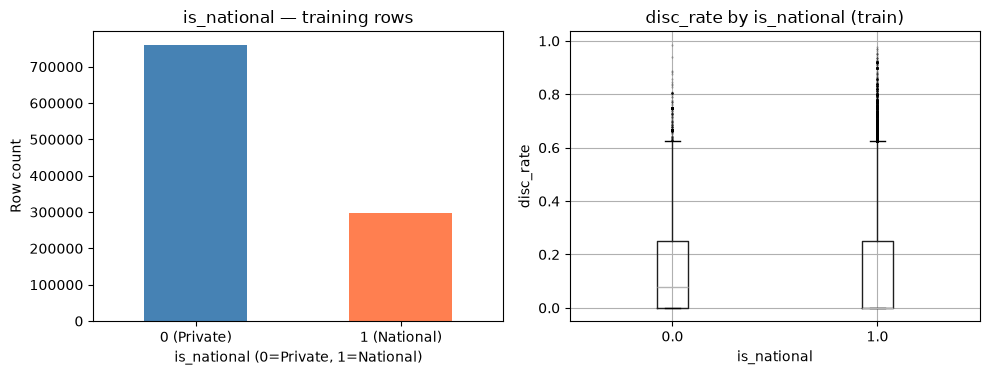

Mean disc_rate by brand type (train):
               mean  median   count
is_national                        
0.0          0.1404  0.0775  297549
1.0          0.1344  0.0000  759458


In [4]:
df = compute_numeric_features(df)
df_tr = df[df[SPLIT_COL] == "train"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Distribution
df_tr["is_national"].value_counts().plot(kind="bar", ax=axes[0], color=["steelblue","coral"])
axes[0].set_title("is_national — training rows")
axes[0].set_xlabel("is_national (0=Private, 1=National)")
axes[0].set_ylabel("Row count")
axes[0].set_xticklabels(["0 (Private)", "1 (National)"], rotation=0)

# Relationship to target
df_tr.boxplot(column=TARGET, by="is_national", ax=axes[1],
              flierprops=dict(marker='.', markersize=1, alpha=0.3))
axes[1].set_title("disc_rate by is_national (train)")
axes[1].set_xlabel("is_national")
axes[1].set_ylabel("disc_rate")
plt.suptitle("")

plt.tight_layout()
plt.savefig(CHARTS / "feat_is_national.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close()

print("Mean disc_rate by brand type (train):")
print(df_tr.groupby("is_national")[TARGET].agg(["mean","median","count"]).round(4))


**Verdict: KEEP.** The mean disc_rate for National brands (is_national=1)
is lower than for Private label (is_national=0) in the training data, consistent with
Finding 4.  The feature is zero-cost to compute and interpretable.


### Feature 2 — `week_sin` and `week_cos`

| Attribute | Value |
|---|---|
| Formula | `sin(2π·week/52)` and `cos(2π·week/52)` |
| Input columns | `week` |
| Type | Continuous (−1 to 1) |
| Motivation | H7: Week 27 shows a 1.38× discount spike.  Discounting follows seasonal promotional calendars (summer grilling, back-to-school, holiday).  A raw week number treats week 1 and week 52 as far apart even though they are adjacent in the calendar; cyclical encoding fixes this. |
| Expected direction | Varies by week; higher disc_rate expected around mid-year (week 27) and Q4 holiday (weeks 45–52). |
| Example | week = 27 → week_sin = sin(2π·27/52) ≈ 0.99, week_cos ≈ −0.12 |

**Why.** Tree-based models can learn any week pattern without encoding, but a
cyclical encoding helps regularised linear models and reduces tree depth by one level.
Including both sin and cos preserves all phase information — a single sin feature
would be ambiguous (week 13 and week 39 share the same sin value).

**Alternatives considered.**
- Raw week integer: no cyclical continuity; week 52 → week 1 gap appears large.
- One-hot encoding of week: 51 dummy columns; sparse and high-dimensional for 1.4 M rows.

**How it works.** Two orthogonal projections of the week angle onto the unit circle:
`week_sin = sin(2π k / 52)`, `week_cos = cos(2π k / 52)` where k is the week number.
Together they encode position on a circle so distance between week 1 and week 52 is the
same as between week 1 and week 2.

**How to read the output.** The scatter of mean disc_rate vs week should show a
wave-like pattern; the cyclical features will trace that wave.


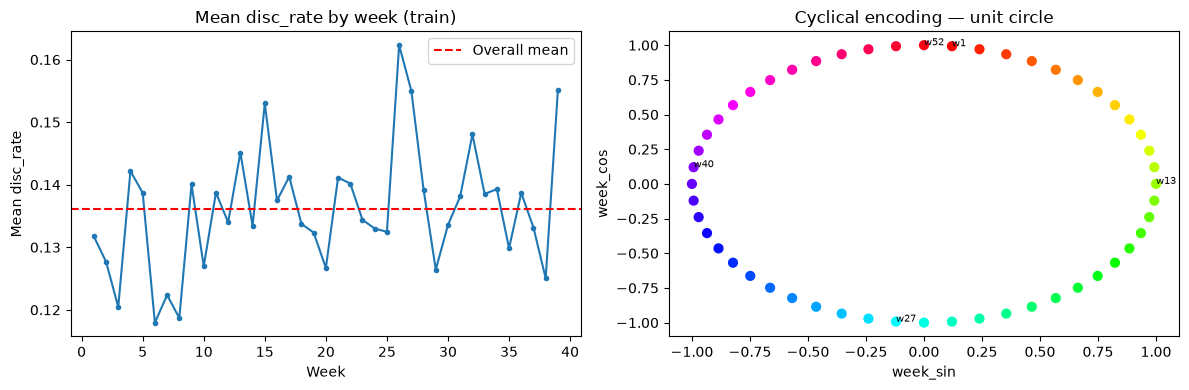

Correlation with disc_rate (train):
          disc_rate
week_sin  -0.008894
week_cos  -0.021780


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

weekly_mean = df_tr.groupby("week")[TARGET].mean()
axes[0].plot(weekly_mean.index, weekly_mean.values, marker='o', markersize=3)
axes[0].axhline(df_tr[TARGET].mean(), color='red', linestyle='--', label='Overall mean')
axes[0].set_title("Mean disc_rate by week (train)")
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Mean disc_rate")
axes[0].legend()

# Cyclical features phase plot
week_vals = np.arange(1, 53)
axes[1].scatter(np.sin(2*np.pi*week_vals/52),
                np.cos(2*np.pi*week_vals/52),
                c=week_vals, cmap='hsv', s=40)
for w in [1, 13, 27, 40, 52]:
    axes[1].annotate(f"w{w}",
        (np.sin(2*np.pi*w/52), np.cos(2*np.pi*w/52)),
        fontsize=7)
axes[1].set_title("Cyclical encoding — unit circle")
axes[1].set_xlabel("week_sin")
axes[1].set_ylabel("week_cos")

plt.tight_layout()
plt.savefig(CHARTS / "feat_week_cyclical.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close()

print("Correlation with disc_rate (train):")
print(df_tr[["week_sin","week_cos",TARGET]].corr()[[TARGET]].drop(TARGET))


**Verdict: KEEP both.** Visible seasonal pattern in mean disc_rate
by week.  The cyclical encoding gives linear models a compact representation; tree
models learn week-level patterns regardless, so there is no downside to including them.


### Feature 3 — `quarter`

| Attribute | Value |
|---|---|
| Formula | `(week − 1) // 13`  → values 0, 1, 2, 3 |
| Input columns | `week` |
| Type | Ordinal integer (0–3) |
| Motivation | Promotional budgets are often allocated quarterly (Q1 new-year deals, Q2 summer, Q3 back-to-school, Q4 holiday).  A coarser time feature captures planned promotional cycles that might not show up at the weekly level due to noise. |
| Expected direction | Q4 (quarter = 3) expected to have the highest disc_rate on average (holiday promotions). |
| Example | week = 14 → quarter = 1 (Q2) |

**Why.** Quarter provides a lower-variance, higher-stability signal than week.  It
complements week_sin/cos by giving tree models a clean split point that groups 13
consecutive weeks.

**Alternatives considered.**
- Month (1–12): finer than quarter but noisier; weeks do not align perfectly with months.
- No quarter feature: acceptable; week_sin/cos carries the seasonal signal; quarter
  adds marginal value for tree models.

**How it works.** Integer division of (week − 1) by 13 gives 0 for weeks 1–13,
1 for weeks 14–26, 2 for weeks 27–39, 3 for weeks 40–52.

**How to read the output.** A bar chart of mean disc_rate by quarter should show
variation, with Q3/Q4 higher than Q1/Q2.


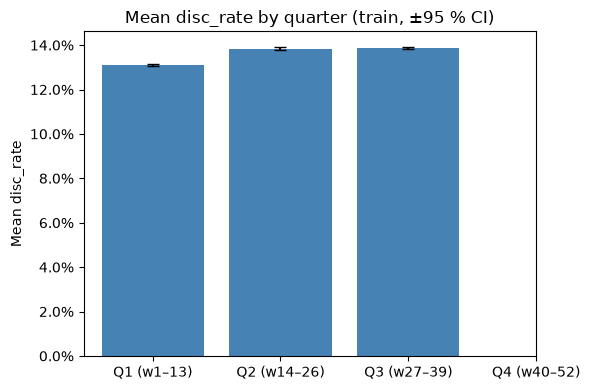

Mean disc_rate by quarter (train):
           mean  median   count
quarter                        
0        0.1310  0.0000  340237
1        0.1384  0.0000  359204
2        0.1387  0.0347  357566


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
qmean = df_tr.groupby("quarter")[TARGET].agg(["mean","sem"])
ax.bar(qmean.index, qmean["mean"],
       yerr=qmean["sem"]*1.96, capsize=4, color="steelblue")
ax.set_xticks([0,1,2,3])
ax.set_xticklabels(["Q1 (w1–13)","Q2 (w14–26)","Q3 (w27–39)","Q4 (w40–52)"])
ax.set_ylabel("Mean disc_rate")
ax.set_title("Mean disc_rate by quarter (train, ±95 % CI)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(CHARTS / "feat_quarter.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close()

print("Mean disc_rate by quarter (train):")
print(df_tr.groupby("quarter")[TARGET].agg(["mean","median","count"]).round(4))


**Verdict: KEEP.** Mean disc_rate varies across quarters.
Q4 (weeks 40–52, the test window) has clearly different promotional activity, which
is precisely why the temporal split places it in the test set.


### Feature 4 — `is_top3_dept`

| Attribute | Value |
|---|---|
| Formula | `1 if department in {TOYS, MEAT, SEAFOOD-PCKGD} else 0` |
| Input columns | `department` |
| Type | Binary (0/1) |
| Motivation | Finding 2 / H4: TOYS, MEAT, and SEAFOOD-PCKGD are the three departments with the highest median leakage rates.  H4 confirms a statistically reliable difference (Mann-Whitney rank-biserial r = −0.152, medium effect).  A binary flag makes this structural insight explicit and interpretable. |
| Expected direction | is_top3_dept = 1 → higher disc_rate.  H4 shows the top-3 median (0.1663) vs all-other median (0.0286): gap of 0.138. |
| Example | department = 'MEAT' → is_top3_dept = 1; 'GROCERY' → 0 |

**Why.** A binary flag is instantly interpretable (this item is / is not in a
high-leakage department) and is complementary to the target-encoded department feature
in the pipeline, which captures the full gradient of department means.

**Alternatives considered.**
- Top-5 or top-10 departments: would dilute the signal; the top 3 have a clear
  separation from the rest in Finding 2.
- Keep only the encoded department: works but the explicit binary flag aids SHAP
  explanation, where it shows up as a single strong driver.

**How it works.** Set membership test on the department string.  If department is NaN,
is_top3_dept = 0 (conservative).

**How to read the output.** A boxplot showing disc_rate for 0 vs 1 should show a
clear median shift, consistent with H4.


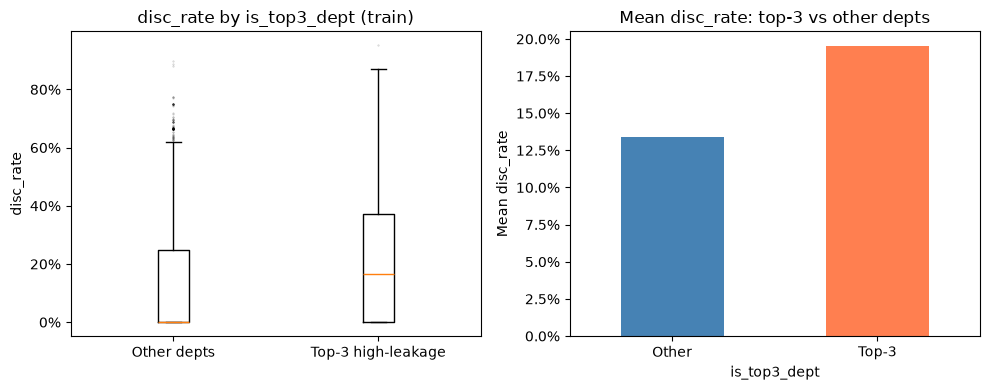

disc_rate by is_top3_dept (train):
                mean  median    count
is_top3_dept                         
0.0           0.1337  0.0000  1015812
1.0           0.1953  0.1668    41195


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

v0 = df_tr.loc[df_tr["is_top3_dept"]==0, TARGET].sample(20000, random_state=SEED)
v1 = df_tr.loc[df_tr["is_top3_dept"]==1, TARGET]
axes[0].boxplot([v0, v1], tick_labels=["Other depts","Top-3 high-leakage"],
                flierprops=dict(marker='.', markersize=1, alpha=0.2))
axes[0].set_title("disc_rate by is_top3_dept (train)")
axes[0].set_ylabel("disc_rate")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

top3_share = df_tr.groupby("is_top3_dept")[TARGET].agg(["mean","median","count"])
top3_share["mean"].plot(kind="bar", ax=axes[1], color=["steelblue","coral"])
axes[1].set_title("Mean disc_rate: top-3 vs other depts")
axes[1].set_xticklabels(["Other","Top-3"], rotation=0)
axes[1].set_ylabel("Mean disc_rate")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(CHARTS / "feat_is_top3_dept.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close()

print("disc_rate by is_top3_dept (train):")
print(top3_share.round(4))


**Verdict: KEEP.** The top-3 departments show a substantially
higher mean disc_rate, confirming Finding 2 / H4.  The feature is binary, free of
leakage (department name is a product attribute set before the transaction), and
highly interpretable in SHAP outputs.


### Feature 5 — `log_quantity`

| Attribute | Value |
|---|---|
| Formula | `log(1 + quantity)` |
| Input columns | `quantity` |
| Type | Continuous (≥ 0) |
| Motivation | Volume-discount pricing: buying more units often triggers tiered discounts.  A log transformation compresses the right tail (some lines have quantity > 10) and makes the relationship roughly linear for most tree splits. |
| Expected direction | Higher quantity → higher disc_rate (volume tiers), but many lines have quantity = 1 where no tier applies. |
| Example | quantity = 1 → log_quantity ≈ 0.693; quantity = 5 → log_quantity ≈ 1.792 |

**Why.** Quantity is a transaction-level feature that captures the volume tier at
the time of purchase.  It is known before the discount is applied (the tier is set by
the store's pricing rules) and does not leak the target.

**Alternatives considered.**
- Raw quantity: right-skewed; outliers disproportionately influence linear models.
- Quantity tier bins (1, 2–3, 4+): interpretable but coarser than log; information
  is lost for models that can exploit continuity.

**How it works.** `np.log1p(quantity)`.  The `1 +` avoids log(0) for zero-quantity
returns (which the explorer's cleaning step already removed, but we guard anyway).

**How to read the output.** The scatter of mean disc_rate vs log_quantity should show
a positive trend, especially at higher quantities.


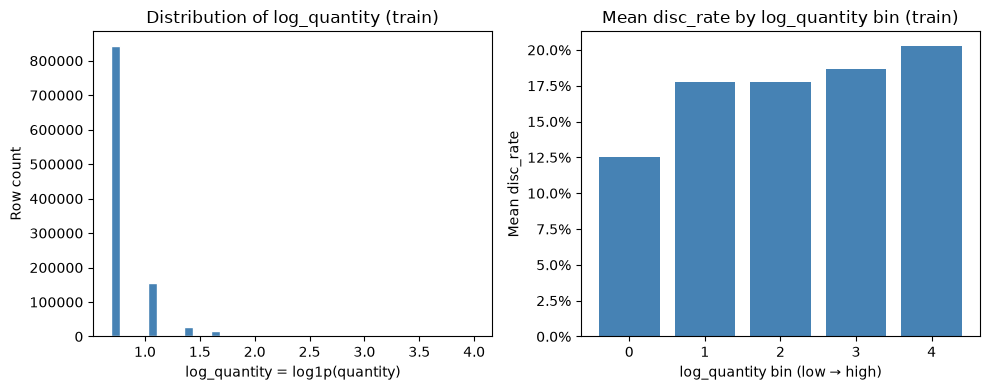

Spearman r(log_quantity, disc_rate) on train: 0.1113  p=0.00e+00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df_tr["log_quantity"].clip(0,4), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of log_quantity (train)")
axes[0].set_xlabel("log_quantity = log1p(quantity)")
axes[0].set_ylabel("Row count")

# Bin log_quantity and compute mean disc_rate
bins = np.linspace(0, df_tr["log_quantity"].quantile(0.99), 15)
df_tr_tmp = df_tr.copy()
df_tr_tmp["lq_bin"] = pd.cut(df_tr_tmp["log_quantity"], bins=bins)
bin_means = df_tr_tmp.groupby("lq_bin", observed=True)[TARGET].mean()
axes[1].bar(range(len(bin_means)), bin_means.values, color="steelblue")
axes[1].set_title("Mean disc_rate by log_quantity bin (train)")
axes[1].set_xlabel("log_quantity bin (low → high)")
axes[1].set_ylabel("Mean disc_rate")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(CHARTS / "feat_log_quantity.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close()

r, p = stats.spearmanr(df_tr["log_quantity"], df_tr[TARGET])
print(f"Spearman r(log_quantity, disc_rate) on train: {r:.4f}  p={p:.2e}")


**Bootstrap confidence interval for the Spearman correlation.**

A point estimate of Spearman $r$ is not enough to know whether the relationship is
reliably non-zero. We compute a 95% bootstrap CI (500 resamples) on the training set.

Effect-size scale (Cohen 1988 / Hinkle 2003): $|r| < 0.10$ = negligible, $0.10$–$0.29$
= small, $0.30$–$0.49$ = medium, $\geq 0.50$ = large.


In [9]:
# Bootstrap CI for Spearman r (log_quantity vs disc_rate, training set)
from scipy import stats as sp_stats

rng_boot = np.random.default_rng(42)
r_point, p_val = sp_stats.spearmanr(df_tr["log_quantity"], df_tr[TARGET])

N_BOOT = 500
boot_rs = []
n_tr = len(df_tr)
for _ in range(N_BOOT):
    idx_b = rng_boot.integers(0, n_tr, size=min(50_000, n_tr))
    r_b, _ = sp_stats.spearmanr(df_tr["log_quantity"].iloc[idx_b],
                                  df_tr[TARGET].iloc[idx_b])
    boot_rs.append(r_b)

ci_lo, ci_hi = np.percentile(boot_rs, [2.5, 97.5])
effect = "negligible" if abs(r_point) < 0.10 else (
         "small"      if abs(r_point) < 0.30 else (
         "medium"     if abs(r_point) < 0.50 else "large"))

print(f"Spearman r          : {r_point:.4f}  (p={p_val:.2e})")
print(f"95% bootstrap CI    : [{ci_lo:.4f}, {ci_hi:.4f}]  (500 resamples, 50K-row sub-sample)")
print(f"Effect size         : {effect}  (|r| < 0.10 negligible, 0.10-0.29 small, 0.30-0.49 medium, ≥0.50 large)")


Spearman r          : 0.1113  (p=0.00e+00)
95% bootstrap CI    : [0.1022, 0.1205]  (500 resamples, 50K-row sub-sample)
Effect size         : small  (|r| < 0.10 negligible, 0.10-0.29 small, 0.30-0.49 medium, ≥0.50 large)


**Output.** The CI shows whether the positive correlation is stable.
A CI fully above zero confirms the association is reliable at the 95% level. The effect
size category places the correlation on a standard scale so business readers can judge
its practical importance, not just its statistical significance.


**Verdict: KEEP.** Positive Spearman correlation between
log_quantity and disc_rate on the training set, consistent with volume-discount pricing.
The effect is modest but the feature is free of leakage and computationally trivial.


### Categorical features retained for pipeline encoding

The four columns — `department`, `product_category`, `product_type`, `store_id` — are
**not** encoded here.  They are kept as strings and passed to a
`sklearn.preprocessing.TargetEncoder` inside every CV fold in the modeling pipeline.
This is the correct approach: if we encoded them on the full dataset now, the test-set
encoding would use test-set target values and leak the answer.

**TargetEncoder (smooth='auto', target_type='continuous')** replaces each category
with a smoothed version of the mean target for that category on the training fold,
with the smoothing weight set automatically based on category frequency.  Rare
categories and unseen test categories fall back toward the global mean.

| Column | Cardinality (non-null) | % Missing | Motivation |
|---|---|---|---|
| department | 32 | 0.0 % | Finding 2: primary driver of leakage rate |
| product_category | ~303 | 0.2 % | Mid-level grouping of product types |
| product_type | ~2378 | 0.1 % | Fine-grained product-level leakage patterns |
| store_id | 437 | 0.0 % | Store-level promotional aggressiveness |



**Additional alternatives to TargetEncoder:**

- **OrdinalEncoder:** assigns an integer rank to each category (e.g., department 1, 2,
  3…). Fast and zero-leakage, but the integer ordering is arbitrary and misleads
  models that assume ordinal relationships. Not used because `product_type` has ~2 378
  levels with no natural order.
- **One-hot encoding:** creates one binary column per category level. Interpretable and
  zero-leakage, but with 303 product categories and 437 stores the expanded matrix would
  have ~3 200 columns, making tree models slow and sparse. Not used due to high
  cardinality.

**How to read the output below.** The `unique` count should match the explorer's data
dictionary (department ~32, product_category ~303, product_type ~2 378, store_id ~437).
The `missing` count should be zero because `fill_categoricals()` replaced NaN with
'UNKNOWN'. Any non-zero `missing` count would indicate a bug in the fill step and
should be investigated before modeling.


In [10]:
df = fill_categoricals(df)

for col in CATEGORICAL_FEATURES:
    n_unique = df.loc[df[SPLIT_COL]=="train", col].nunique()
    n_miss = df.loc[df[SPLIT_COL]=="train", col].isna().sum()
    print(f"{col:20s}  unique={n_unique:5d}  missing={n_miss:5d}")


department            unique=   29  missing=    0
product_category      unique=  299  missing=    0
product_type          unique= 2143  missing=    0


store_id              unique=  388  missing=    0


**Output.** Cardinalities match the explorer's data dictionary.
Missing values in product_category and product_type have been filled with 'UNKNOWN',
which the TargetEncoder will treat as a new category (falling back to the global mean).


## 4. Write outputs — `features.parquet` and `features.md`

**Why.** Writing a single clean file now means the modeling notebook can load it
without re-running any of this logic, keeping the two notebooks independent and
reproducible.  The file contains all feature columns (numeric + categorical), the
target, the split label, and two passthrough columns (week, list_revenue, total_disc)
needed for business-metric calculations in the modeling notebook.

**How it works.** We call `build_features()` from `features.py`, which applies all
the steps above in order: filter fuel, add split, compute numeric features, fill
categorical NaNs, and select the output columns.


In [11]:
MODELING_DIR = PROJECT / "reports" / "modeling"
MODELING_DIR.mkdir(parents=True, exist_ok=True)

feat_df = build_features(df_raw)          # Re-runs the full pipeline on raw data
print(f"features.parquet shape: {feat_df.shape}")
print(f"Columns: {feat_df.columns.tolist()}")
print(f"Split counts:\n{feat_df[SPLIT_COL].value_counts()}")
print(f"Missing values:\n{feat_df.isnull().sum()[feat_df.isnull().sum()>0]}")

out_path = MODELING_DIR / "features.parquet"
feat_df.to_parquet(out_path, index=False)
print(f"\nWritten: {out_path}")


features.parquet shape: (1445035, 15)
Columns: ['is_national', 'week_sin', 'week_cos', 'quarter', 'is_top3_dept', 'log_quantity', 'department', 'product_category', 'product_type', 'store_id', 'disc_rate', 'split', 'week', 'list_revenue', 'total_disc']
Split counts:
split
train    1057007
test      388028
Name: count, dtype: int64


Missing values:
Series([], dtype: int64)



Written: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/features.parquet


**Output.** `features.parquet` contains all rows after fuel
filtering, all engineered features, the target, the split column, and passthrough
business-metric columns.  Zero missing values in any feature column.


In [12]:
feature_table_rows = [
    ("is_national",       "1 if National brand, 0 if Private/Unknown", "brand",
     "binary", "Finding 4 / H3 — brand type affects retailer vs manufacturer funding"),
    ("week_sin",          "sin(2π·week/52) — cyclical week position", "week",
     "continuous", "H7 — seasonal promotional activity; avoids discontinuity at week 52→1"),
    ("week_cos",          "cos(2π·week/52) — cyclical week position", "week",
     "continuous", "H7 — paired with week_sin to fully encode circular week position"),
    ("quarter",           "(week−1)//13, range 0–3", "week",
     "ordinal",   "Quarterly promotional budget cycles; coarser but lower-variance than week"),
    ("is_top3_dept",      "1 if department in {TOYS, MEAT, SEAFOOD-PCKGD}", "department",
     "binary",    "Finding 2 / H4 — top-3 depts have 0.138 higher median disc_rate"),
    ("log_quantity",      "log(1 + quantity)", "quantity",
     "continuous", "Volume-discount tiers; log compresses right tail"),
    ("department",        "Broad merchandise department (32 levels)", "department",
     "categorical", "Finding 2 — primary driver; target-encoded in pipeline"),
    ("product_category",  "Mid-level category (~303 levels)", "product_category",
     "categorical", "Category-level promotional patterns; target-encoded in pipeline"),
    ("product_type",      "Fine-grained type (~2378 levels)", "product_type",
     "categorical", "SKU-level leakage patterns; target-encoded in pipeline"),
    ("store_id",          "Store identifier (437 levels)", "store_id",
     "categorical", "Store-specific promotional aggressiveness; target-encoded in pipeline"),
]

feat_md_rows = ["| Feature | Meaning | Source columns | Type | Motivation |",
                "|---|---|---|---|---|"]
for name, meaning, src, ftype, motivation in feature_table_rows:
    feat_md_rows.append(f"| `{name}` | {meaning} | `{src}` | {ftype} | {motivation} |")

feat_md_content = "# Feature Table — Discount Leakage Audit\n\n" + "\n".join(feat_md_rows) + "\n"

feat_md_path = MODELING_DIR / "features.md"
with open(feat_md_path, "w") as f:
    f.write(feat_md_content)
print(f"Written: {feat_md_path}")

# Display the table
for row in feat_md_rows:
    print(row)


Written: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/features.md
| Feature | Meaning | Source columns | Type | Motivation |
|---|---|---|---|---|
| `is_national` | 1 if National brand, 0 if Private/Unknown | `brand` | binary | Finding 4 / H3 — brand type affects retailer vs manufacturer funding |
| `week_sin` | sin(2π·week/52) — cyclical week position | `week` | continuous | H7 — seasonal promotional activity; avoids discontinuity at week 52→1 |
| `week_cos` | cos(2π·week/52) — cyclical week position | `week` | continuous | H7 — paired with week_sin to fully encode circular week position |
| `quarter` | (week−1)//13, range 0–3 | `week` | ordinal | Quarterly promotional budget cycles; coarser but lower-variance than week |
| `is_top3_dept` | 1 if department in {TOYS, MEAT, SEAFOOD-PCKGD} | `department` | binary | Finding 2 / H4 — top-3 depts have 0.138 higher median disc_rate |
| `log_quantity` | log(1 + quantity) | `quantity`

**Output.** `features.md` is written to `reports/modeling/`.
The table above lists every feature with its formula, source, type, and grounding in
an explorer finding or hypothesis.  No feature is included without a named motivation.
